# DDXPlus Respiratory Dataset – Exploratory Data Analysis

## IS Project 2 – Respiratory Health Awareness and Prediction System

This notebook explores the prepared DDXPlus respiratory dataset before model training.

The analysis focuses on:

- dataset structure and split sizes
- respiratory disease distribution
- class imbalance
- age distribution
- sex distribution
- evidence and symptom feature usage
- missing values
- preparation of figures for model development and project documentation

The dataset contains 21 respiratory conditions selected using ICD-10 Chapter J, together with Tuberculosis, Pulmonary neoplasm and Whooping cough.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path("..")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
METRICS_DIR = RESULTS_DIR / "metrics"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Processed data:", PROCESSED_DIR.resolve())
print("Figures folder:", FIGURES_DIR.resolve())
print("Metrics folder:", METRICS_DIR.resolve())

Processed data: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\data\processed
Figures folder: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures
Metrics folder: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics


In [2]:
with open(PROCESSED_DIR / "features.json", "r", encoding="utf-8") as f:
    features = json.load(f)

with open(PROCESSED_DIR / "diseases.json", "r", encoding="utf-8") as f:
    diseases = json.load(f)

print("Number of model features:", len(features))
print("Number of diseases:", len(diseases))

print("\nFirst 10 model features:")
print(features[:10])

Number of model features: 797
Number of diseases: 21

First 10 model features:
['AGE', 'SEX_M', 'E_2', 'E_4', 'E_5', 'E_8', 'E_14', 'E_17', 'E_18', 'E_20']


In [3]:
diseases_df = pd.DataFrame(diseases)

diseases_df

,name,icd10,severity
0,Acute COPD exacerbation / infection,J44.1,3
1,Acute laryngitis,J04.0,4
2,Acute pulmonary edema,J81.0,1
3,Acute rhinosinusitis,J01,4
4,Allergic sinusitis,J30,4
5,Bronchiectasis,J47,3
6,Bronchiolitis,J21,3
7,Bronchitis,J40,4
8,Bronchospasm / acute asthma exacerbation,J45,3
9,Chronic rhinosinusitis,J32,5


In [4]:
basic_columns = [
    "AGE",
    "SEX_M",
    "PATHOLOGY",
    "INITIAL_EVIDENCE"
]

train_basic = pd.read_csv(
    PROCESSED_DIR / "train.csv",
    usecols=basic_columns
)

validate_basic = pd.read_csv(
    PROCESSED_DIR / "validate.csv",
    usecols=basic_columns
)

test_basic = pd.read_csv(
    PROCESSED_DIR / "test.csv",
    usecols=basic_columns
)

print("Train shape:", train_basic.shape)
print("Validation shape:", validate_basic.shape)
print("Test shape:", test_basic.shape)

Train shape: (443075, 4)
Validation shape: (55808, 4)
Test shape: (56817, 4)


In [5]:
train_basic.head(10)

,AGE,SEX_M,PATHOLOGY,INITIAL_EVIDENCE
0,18,1,URTI,E_91
1,19,0,Pneumonia,E_77
2,34,0,URTI,E_53
3,36,1,URTI,E_201
4,37,0,Chronic rhinosinusitis,E_53
5,43,1,Viral pharyngitis,E_53
6,30,1,Chronic rhinosinusitis,E_53
7,8,1,Allergic sinusitis,E_169
8,3,0,Larygospasm,E_194
9,47,1,Viral pharyngitis,E_201


In [6]:
split_summary = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Patients": [
        len(train_basic),
        len(validate_basic),
        len(test_basic)
    ]
})

split_summary

,Split,Patients
0,Train,443075
1,Validation,55808
2,Test,56817


In [7]:
total_patients = split_summary["Patients"].sum()

print(f"Total respiratory patients: {total_patients:,}")

Total respiratory patients: 555,700


In [8]:
print("Training diseases:", train_basic["PATHOLOGY"].nunique())
print("Validation diseases:", validate_basic["PATHOLOGY"].nunique())
print("Test diseases:", test_basic["PATHOLOGY"].nunique())

print("\nMissing values in training basic columns:")
print(train_basic.isnull().sum())

Training diseases: 21
Validation diseases: 21
Test diseases: 21

Missing values in training basic columns:
AGE                 0
SEX_M               0
PATHOLOGY           0
INITIAL_EVIDENCE    0
dtype: int64


## 2. Disease Distribution and Class Imbalance

This section examines the number of patients belonging to each respiratory condition across the training, validation and test datasets. The analysis is important because large differences in class size can affect model performance and make overall accuracy misleading.

In [9]:
train_counts = train_basic["PATHOLOGY"].value_counts()
validate_counts = validate_basic["PATHOLOGY"].value_counts()
test_counts = test_basic["PATHOLOGY"].value_counts()

disease_distribution = pd.DataFrame({
    "Train": train_counts,
    "Validation": validate_counts,
    "Test": test_counts
}).fillna(0).astype(int)

disease_distribution["Total"] = (
    disease_distribution["Train"]
    + disease_distribution["Validation"]
    + disease_distribution["Test"]
)

disease_distribution = disease_distribution.sort_values(
    "Train",
    ascending=False
)

disease_distribution

,Train,Validation,Test,Total
PATHOLOGY,,,,
URTI,64368,8656,8743,81767
Viral pharyngitis,61642,8246,8334,78222
Influenza,26812,3590,3554,33956
Bronchitis,26400,3543,3594,33537
Allergic sinusitis,26203,2136,2411,30750
Pneumonia,25761,3484,3542,32787
Acute laryngitis,24129,3407,3217,30753
Chronic rhinosinusitis,20579,2717,2747,26043
Bronchospasm / acute asthma exacerbation,19875,2209,2222,24306


In [10]:
disease_distribution["Train_%"] = (
    disease_distribution["Train"]
    / disease_distribution["Train"].sum()
    * 100
)

disease_distribution[
    ["Train", "Train_%", "Validation", "Test", "Total"]
].round(2)

,Train,Train_%,Validation,Test,Total
PATHOLOGY,,,,,
URTI,64368,14.53,8656,8743,81767
Viral pharyngitis,61642,13.91,8246,8334,78222
Influenza,26812,6.05,3590,3554,33956
Bronchitis,26400,5.96,3543,3594,33537
Allergic sinusitis,26203,5.91,2136,2411,30750
Pneumonia,25761,5.81,3484,3542,32787
Acute laryngitis,24129,5.45,3407,3217,30753
Chronic rhinosinusitis,20579,4.64,2717,2747,26043
Bronchospasm / acute asthma exacerbation,19875,4.49,2209,2222,24306


In [11]:
distribution_output = METRICS_DIR / "disease_distribution.csv"

disease_distribution.to_csv(distribution_output)

print("Saved to:", distribution_output.resolve())

Saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\disease_distribution.csv


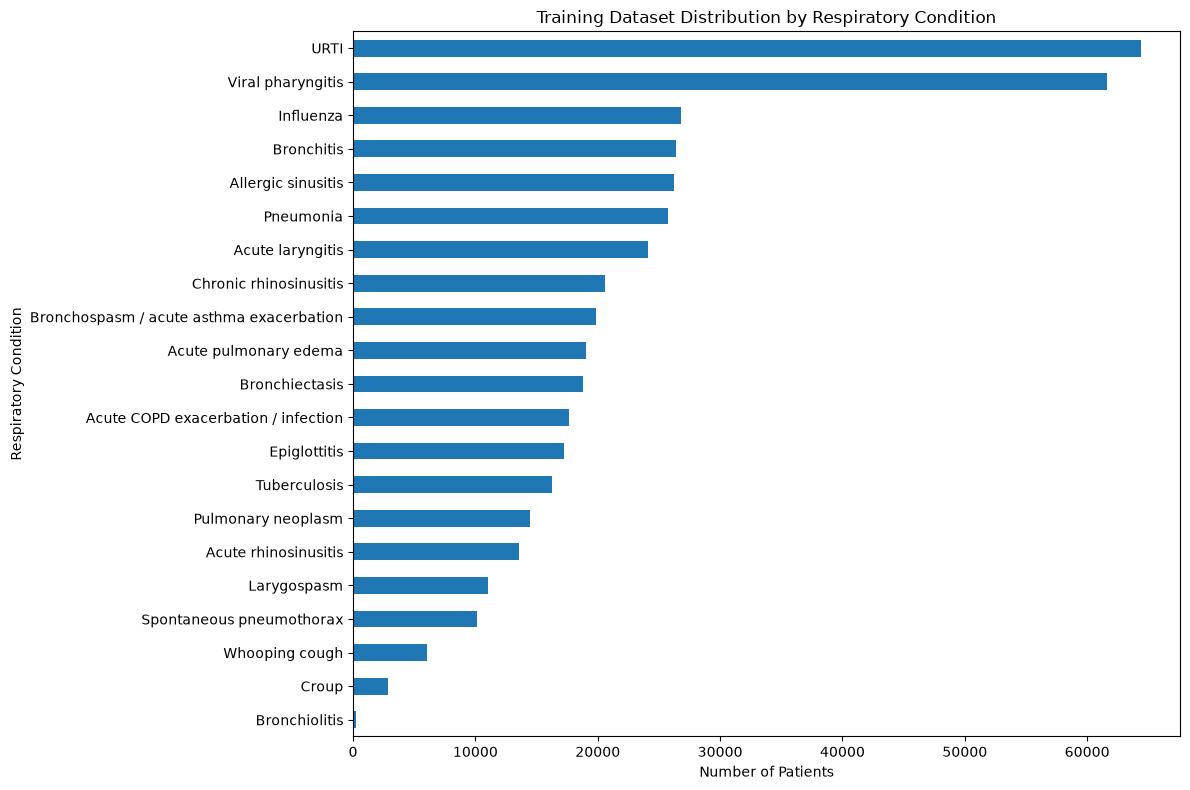

Figure saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures\training_disease_distribution.png


In [12]:
plt.figure(figsize=(12, 8))

disease_distribution["Train"].sort_values().plot(
    kind="barh"
)

plt.title("Training Dataset Distribution by Respiratory Condition")
plt.xlabel("Number of Patients")
plt.ylabel("Respiratory Condition")

plt.tight_layout()

figure_path = FIGURES_DIR / "training_disease_distribution.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", figure_path.resolve())

In [13]:
largest_class = disease_distribution["Train"].idxmax()
largest_count = disease_distribution["Train"].max()

smallest_class = disease_distribution["Train"].idxmin()
smallest_count = disease_distribution["Train"].min()

imbalance_ratio = largest_count / smallest_count

print("Largest training class:")
print(f"{largest_class}: {largest_count:,} patients")

print("\nSmallest training class:")
print(f"{smallest_class}: {smallest_count:,} patients")

print(f"\nImbalance ratio: {imbalance_ratio:.1f}:1")

Largest training class:
URTI: 64,368 patients

Smallest training class:
Bronchiolitis: 261 patients

Imbalance ratio: 246.6:1


In [14]:
disease_distribution[
    ["Train", "Validation", "Test"]
].sort_values("Train").head(5)

,Train,Validation,Test
PATHOLOGY,,,
Bronchiolitis,261,28,36
Croup,2852,267,344
Whooping cough,6070,545,549
Spontaneous pneumothorax,10162,1405,1343
Larygospasm,10998,668,785


### Class Imbalance Observation

The respiratory dataset is strongly imbalanced. Some conditions contain tens of thousands of training examples, while the least represented conditions contain far fewer examples. This means that overall accuracy alone may give a misleading view of model performance because predictions for common diseases can dominate the metric.

For this reason, model evaluation will also consider macro-averaged precision, recall and F1-score, together with per-class recall and the confusion matrix.

## 3. Age Distribution

This section examines the age distribution of patients in the respiratory dataset. Age is an important feature because some respiratory conditions occur more frequently in particular age groups, such as bronchiolitis and croup in younger patients and chronic respiratory conditions in older patients.

In [15]:
age_summary = pd.DataFrame({
    "Train": train_basic["AGE"].describe(),
    "Validation": validate_basic["AGE"].describe(),
    "Test": test_basic["AGE"].describe()
})

age_summary.round(2)

,Train,Validation,Test
count,443075.00,55808.00,56817.00
mean,39.63,39.81,39.66
std,23.06,23.08,23.19
min,0.00,0.00,0.00
25%,22.00,22.00,21.00
50%,39.00,39.00,39.00
75%,56.00,57.00,57.00
max,109.00,109.00,109.00


In [16]:
print("Training age range:")
print(
    f"{train_basic['AGE'].min()} to "
    f"{train_basic['AGE'].max()} years"
)

print("\nMean training age:")
print(f"{train_basic['AGE'].mean():.2f} years")

print("\nMedian training age:")
print(f"{train_basic['AGE'].median():.0f} years")

Training age range:
0 to 109 years

Mean training age:
39.63 years

Median training age:
39 years


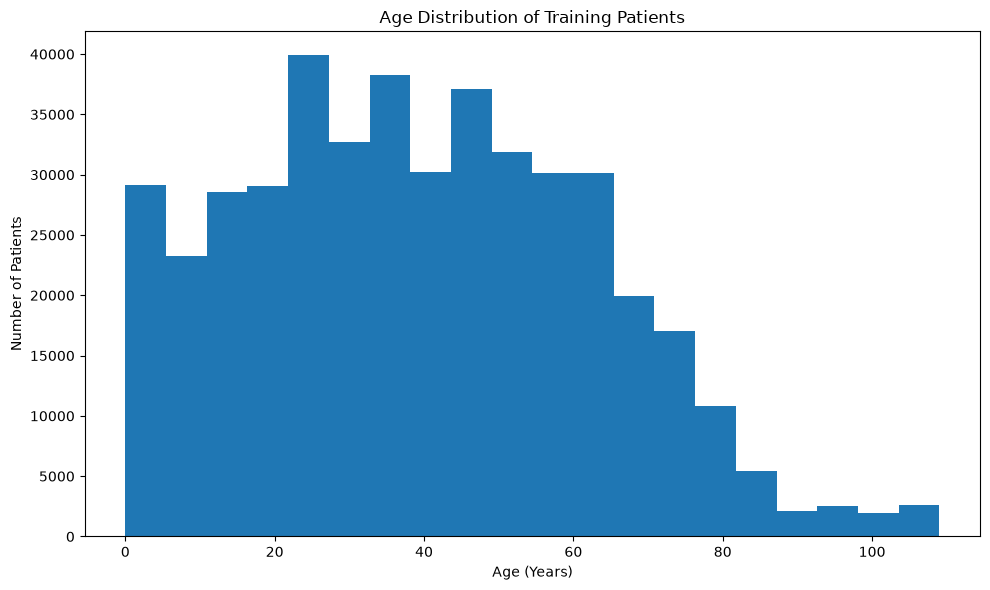

Figure saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures\training_age_distribution.png


In [17]:
plt.figure(figsize=(10, 6))

plt.hist(
    train_basic["AGE"],
    bins=20
)

plt.title("Age Distribution of Training Patients")
plt.xlabel("Age (Years)")
plt.ylabel("Number of Patients")

plt.tight_layout()

age_figure_path = FIGURES_DIR / "training_age_distribution.png"

plt.savefig(
    age_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", age_figure_path.resolve())

In [18]:
age_bins = [
    0,
    5,
    12,
    18,
    30,
    45,
    60,
    75,
    float("inf")
]

age_labels = [
    "0–4",
    "5–11",
    "12–17",
    "18–29",
    "30–44",
    "45–59",
    "60–74",
    "75+"
]

train_basic["AGE_GROUP"] = pd.cut(
    train_basic["AGE"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

age_group_counts = (
    train_basic["AGE_GROUP"]
    .value_counts()
    .sort_index()
)

age_group_counts

AGE_GROUP
0–4      24764
5–11     32370
12–17    28894
18–29    76770
30–44    94738
45–59    92824
60–74    62141
75+      30574
Name: count, dtype: int64

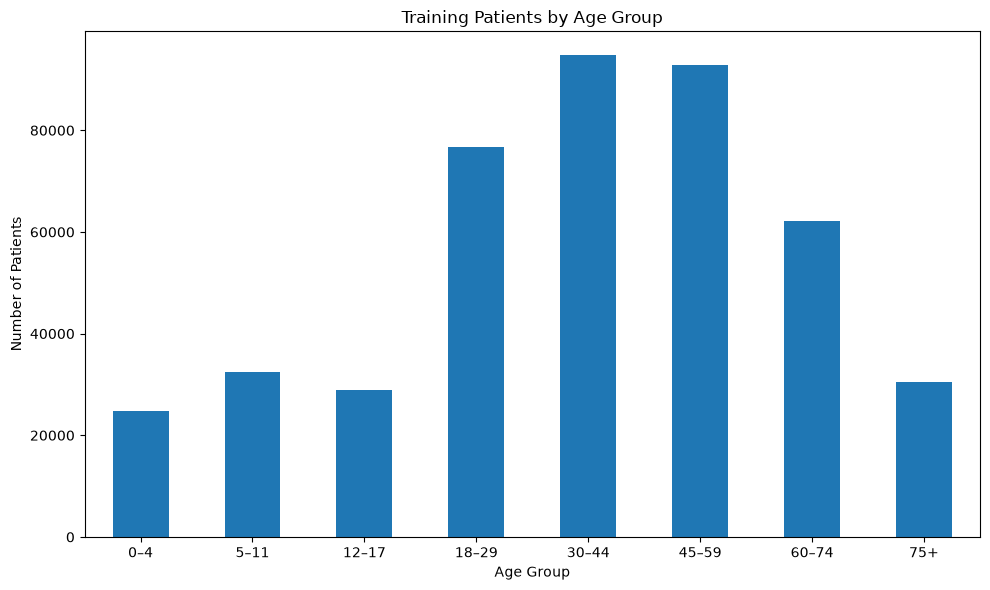

Figure saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures\training_age_groups.png


In [19]:
plt.figure(figsize=(10, 6))

age_group_counts.plot(
    kind="bar"
)

plt.title("Training Patients by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)

plt.tight_layout()

age_group_figure_path = (
    FIGURES_DIR / "training_age_groups.png"
)

plt.savefig(
    age_group_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    age_group_figure_path.resolve()
)

In [20]:
age_by_disease = (
    train_basic
    .groupby("PATHOLOGY")["AGE"]
    .agg(
        Patients="count",
        Mean_Age="mean",
        Median_Age="median",
        Min_Age="min",
        Max_Age="max"
    )
    .sort_values("Median_Age")
)

age_by_disease.round(2)

,Patients,Mean_Age,Median_Age,Min_Age,Max_Age
PATHOLOGY,,,,,
Bronchiolitis,261,0.30,0.0,0,1
Croup,2852,4.07,4.0,0,9
Epiglottitis,17209,27.82,25.0,0,109
Influenza,26812,36.41,34.0,0,109
Bronchospasm / acute asthma exacerbation,19875,37.85,36.0,0,109
Bronchitis,26400,37.55,36.0,0,109
Pneumonia,25761,37.37,36.0,0,109
Tuberculosis,16245,37.50,36.0,0,109
URTI,64368,37.73,36.0,0,109


In [21]:
age_by_disease.to_csv(
    METRICS_DIR / "age_by_disease.csv"
)

print(
    "Saved to:",
    (METRICS_DIR / "age_by_disease.csv").resolve()
)

Saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\age_by_disease.csv


### Age Distribution Observation

The dataset contains patients from a wide range of ages. The age distribution also differs between respiratory conditions, showing that age may provide useful information for distinguishing between diseases.

Age will therefore be retained as an input feature during model training.


## 4. Sex Distribution

This section examines the distribution of male and female patients in the respiratory dataset. Sex is included as a model feature because some respiratory conditions may occur at different frequencies between males and females.

In [22]:
sex_counts = train_basic["SEX_M"].value_counts().sort_index()

sex_distribution = pd.DataFrame({
    "Sex": ["Female", "Male"],
    "Patients": [
        sex_counts.get(0, 0),
        sex_counts.get(1, 0)
    ]
})

sex_distribution["Percentage"] = (
    sex_distribution["Patients"]
    / sex_distribution["Patients"].sum()
    * 100
)

sex_distribution.round(2)

,Sex,Patients,Percentage
0,Female,226617,51.15
1,Male,216458,48.85


In [23]:
female_count = (train_basic["SEX_M"] == 0).sum()
male_count = (train_basic["SEX_M"] == 1).sum()

print(f"Female patients: {female_count:,}")
print(f"Male patients: {male_count:,}")

print(
    f"\nFemale percentage: "
    f"{female_count / len(train_basic) * 100:.2f}%"
)

print(
    f"Male percentage: "
    f"{male_count / len(train_basic) * 100:.2f}%"
)

Female patients: 226,617
Male patients: 216,458

Female percentage: 51.15%
Male percentage: 48.85%


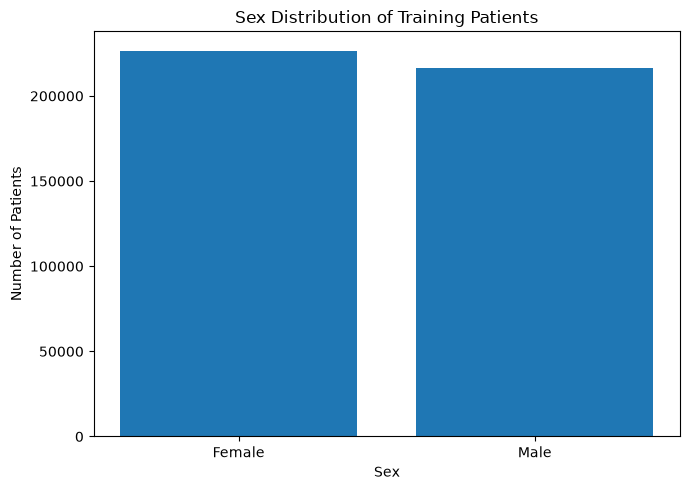

Figure saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures\training_sex_distribution.png


In [24]:
plt.figure(figsize=(7, 5))

plt.bar(
    sex_distribution["Sex"],
    sex_distribution["Patients"]
)

plt.title("Sex Distribution of Training Patients")
plt.xlabel("Sex")
plt.ylabel("Number of Patients")

plt.tight_layout()

sex_figure_path = FIGURES_DIR / "training_sex_distribution.png"

plt.savefig(
    sex_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", sex_figure_path.resolve())

In [25]:
sex_by_disease = pd.crosstab(
    train_basic["PATHOLOGY"],
    train_basic["SEX_M"]
)

sex_by_disease = sex_by_disease.rename(
    columns={
        0: "Female",
        1: "Male"
    }
)

sex_by_disease["Total"] = (
    sex_by_disease["Female"]
    + sex_by_disease["Male"]
)

sex_by_disease["Female_%"] = (
    sex_by_disease["Female"]
    / sex_by_disease["Total"]
    * 100
)

sex_by_disease["Male_%"] = (
    sex_by_disease["Male"]
    / sex_by_disease["Total"]
    * 100
)

sex_by_disease.round(2)

SEX_M,Female,Male,Total,Female_%,Male_%
PATHOLOGY,,,,,
Acute COPD exacerbation / infection,7549,10112,17661,42.74,57.26
Acute laryngitis,12423,11706,24129,51.49,48.51
Acute pulmonary edema,9819,9199,19018,51.63,48.37
Acute rhinosinusitis,7156,6422,13578,52.70,47.30
Allergic sinusitis,13383,12820,26203,51.07,48.93
Bronchiectasis,9644,9151,18795,51.31,48.69
Bronchiolitis,138,123,261,52.87,47.13
Bronchitis,13694,12706,26400,51.87,48.13
Bronchospasm / acute asthma exacerbation,10309,9566,19875,51.87,48.13


In [26]:
sex_by_disease.to_csv(
    METRICS_DIR / "sex_by_disease.csv"
)

print(
    "Saved to:",
    (METRICS_DIR / "sex_by_disease.csv").resolve()
)

Saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\sex_by_disease.csv


### Sex Distribution Observation

The training dataset is relatively balanced by sex, with approximately 51% female and 49% male patients. Most respiratory conditions show a similar distribution, although some conditions, such as acute COPD exacerbation or infection, contain a higher proportion of male patients.

Sex will therefore remain as an input feature because some condition-specific differences are present.

## 5. Evidence and Symptom Feature Analysis

This section examines how frequently the encoded symptom and history features occur in the training dataset. Understanding feature usage helps identify common respiratory evidence, rare features and features that may contribute little information during model training.

In [27]:
RAW_DIR = PROJECT_ROOT / "data" / "raw"

with open(
    RAW_DIR / "release_evidences.json",
    "r",
    encoding="utf-8"
) as f:
    evidence_metadata = json.load(f)

print("Evidence definitions:", len(evidence_metadata))

Evidence definitions: 223


In [28]:
def feature_label(feature):
    if feature in ["AGE", "SEX_M"]:
        return feature

    if "_@_" in feature:
        code, value = feature.split("_@_", 1)
    else:
        code = feature
        value = None

    evidence = evidence_metadata.get(code, {})

    question = evidence.get(
        "question_en",
        code
    )

    if value is None:
        return question

    meaning = (
        evidence
        .get("value_meaning", {})
        .get(value)
    )

    if isinstance(meaning, dict):
        meaning = (
            meaning.get("en")
            or meaning.get("fr")
            or value
        )

    elif meaning is None:
        meaning = value

    return f"{question} — {meaning}"

In [29]:
print(feature_label("E_91"))
print(feature_label("E_55_@_V_89"))
print(feature_label("E_56"))

Do you have a fever (either felt or measured with a thermometer)?
Do you feel pain somewhere? — forehead
How intense is the pain?


In [30]:
evidence_features = [
    feature
    for feature in features
    if feature not in ["AGE", "SEX_M"]
]

print("Evidence feature columns:", len(evidence_features))

Evidence feature columns: 795


In [31]:
active_counts = pd.Series(
    0,
    index=evidence_features,
    dtype="int64"
)

chunk_size = 20000
processed_rows = 0

for chunk in pd.read_csv(
    PROCESSED_DIR / "train.csv",
    usecols=evidence_features,
    dtype="int16",
    chunksize=chunk_size
):
    active_counts = active_counts.add(
        chunk.ne(0).sum(),
        fill_value=0
    ).astype("int64")

    processed_rows += len(chunk)

    if processed_rows % 100000 < chunk_size:
        print(
            f"Processed {processed_rows:,} patients..."
        )

print(
    f"Finished processing {processed_rows:,} patients."
)

Processed 100,000 patients...
Processed 200,000 patients...
Processed 300,000 patients...
Processed 400,000 patients...
Finished processing 443,075 patients.


In [32]:
feature_usage = pd.DataFrame({
    "Feature": active_counts.index,
    "Active_Patients": active_counts.values
})

feature_usage["Percentage"] = (
    feature_usage["Active_Patients"]
    / len(train_basic)
    * 100
)

feature_usage["Label"] = (
    feature_usage["Feature"]
    .apply(feature_label)
)

feature_usage["Evidence_Code"] = (
    feature_usage["Feature"]
    .str.split("_@_")
    .str[0]
)

feature_usage["Kind"] = (
    feature_usage["Evidence_Code"]
    .map(
        lambda code:
        "History"
        if evidence_metadata.get(code, {}).get(
            "is_antecedent",
            False
        )
        else "Symptom"
    )
)

feature_usage = feature_usage.sort_values(
    "Active_Patients",
    ascending=False
)

feature_usage.head(20)[
    [
        "Feature",
        "Label",
        "Kind",
        "Active_Patients",
        "Percentage"
    ]
].round(2)

,Feature,Label,Kind,Active_Patients,Percentage
22,E_53,"Do you have pain somewhere, related to your re...",Symptom,321145,72.48
204,E_56,How intense is the pain?,Symptom,321145,72.48
370,E_58,How precisely is the pain located?,Symptom,316843,71.51
371,E_59,How fast did the pain appear?,Symptom,274417,61.93
768,E_201,Do you have a cough?,Symptom,274343,61.92
205,E_57_@_V_123,Does the pain radiate to another location? — n...,Symptom,271104,61.19
382,E_79,Do you smoke cigarettes?,History,206480,46.60
757,E_181,Do you have nasal congestion or a clear runny ...,Symptom,174704,39.43
387,E_91,Do you have a fever (either felt or measured w...,Symptom,171212,38.64
27,E_54_@_V_161,Characterize your pain: — sensitive,Symptom,148804,33.58


In [33]:
feature_usage.to_csv(
    METRICS_DIR / "feature_usage.csv",
    index=False
)

print(
    "Saved to:",
    (METRICS_DIR / "feature_usage.csv").resolve()
)

Saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\feature_usage.csv


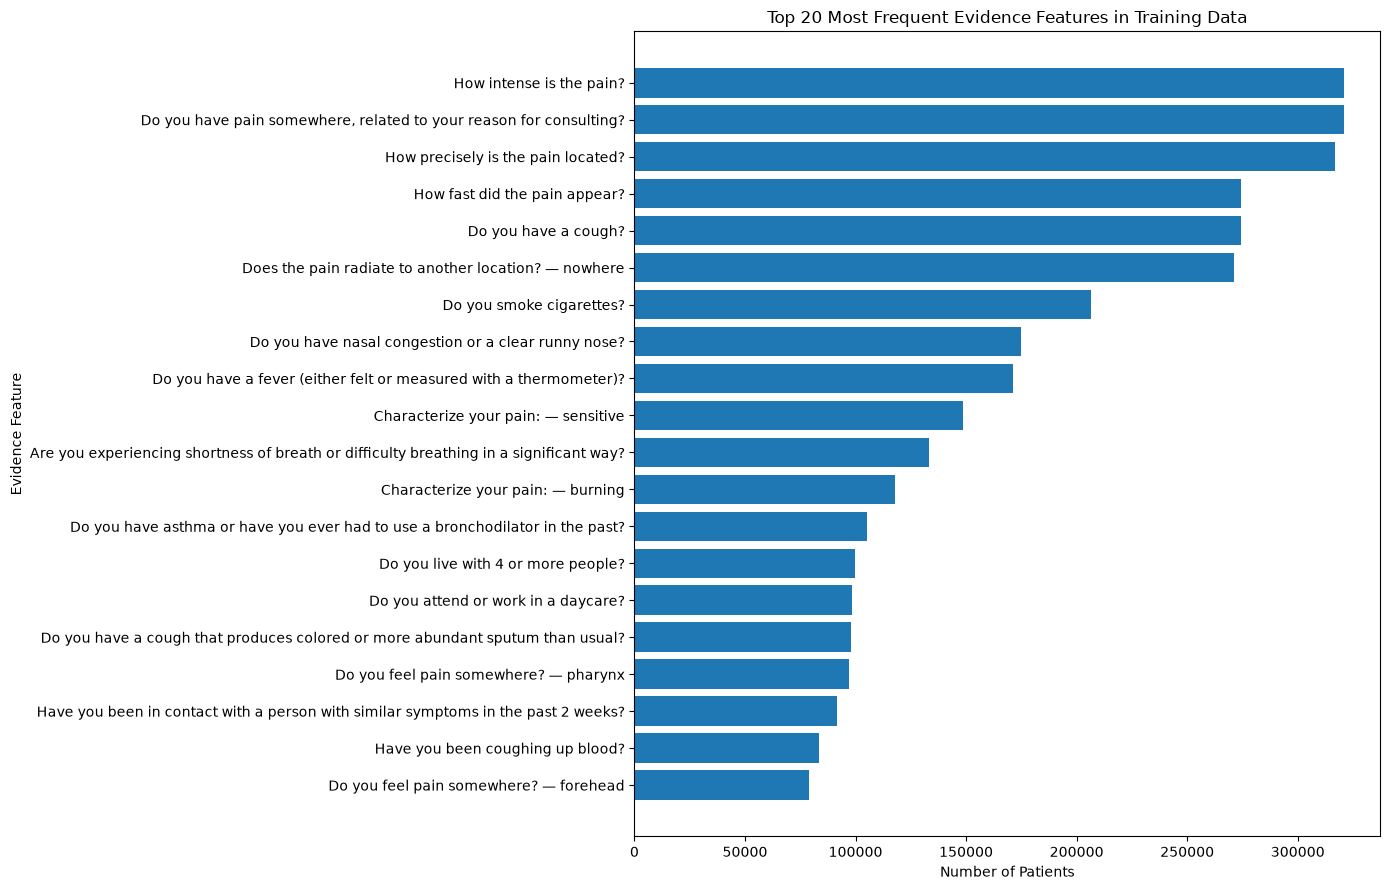

Figure saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\figures\top_20_evidence_features.png


In [34]:
top_features = (
    feature_usage
    .head(20)
    .sort_values("Active_Patients")
)

plt.figure(figsize=(14, 9))

plt.barh(
    top_features["Label"],
    top_features["Active_Patients"]
)

plt.title(
    "Top 20 Most Frequent Evidence Features in Training Data"
)
plt.xlabel("Number of Patients")
plt.ylabel("Evidence Feature")

plt.tight_layout()

feature_figure_path = (
    FIGURES_DIR / "top_20_evidence_features.png"
)

plt.savefig(
    feature_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    feature_figure_path.resolve()
)

In [35]:
unused_features = feature_usage[
    feature_usage["Active_Patients"] == 0
]

rare_features = feature_usage[
    (feature_usage["Active_Patients"] > 0)
    & (feature_usage["Percentage"] < 0.1)
]

print(
    "Unused evidence features:",
    len(unused_features)
)

print(
    "Rare evidence features (<0.1% of training patients):",
    len(rare_features)
)

Unused evidence features: 599
Rare evidence features (<0.1% of training patients): 7


In [36]:
rare_features[
    [
        "Feature",
        "Label",
        "Active_Patients",
        "Percentage"
    ]
].sort_values(
    "Active_Patients"
).head(20).round(3)

,Feature,Label,Active_Patients,Percentage
585,E_152_@_V_123,Where is the swelling located? — nowhere,16,0.004
9,E_23,Do you ever temporarily stop breathing while y...,144,0.033
763,E_195,Do you live in the suburbs?,144,0.033
582,E_142,Does your mother suffer from asthma?,147,0.033
759,E_183,Do you live in a rural area?,148,0.033
11,E_32,Do you have a decrease in appetite?,151,0.034
203,E_55_@_V_197,Do you feel pain somewhere? — epigastric,260,0.059


In [37]:
initial_evidence = (
    train_basic["INITIAL_EVIDENCE"]
    .value_counts()
    .rename_axis("Evidence")
    .reset_index(name="Patients")
)

initial_evidence["Percentage"] = (
    initial_evidence["Patients"]
    / len(train_basic)
    * 100
)

initial_evidence["Label"] = (
    initial_evidence["Evidence"]
    .apply(feature_label)
)

initial_evidence.head(10)[
    [
        "Evidence",
        "Label",
        "Patients",
        "Percentage"
    ]
].round(2)

,Evidence,Label,Patients,Percentage
0,E_53,"Do you have pain somewhere, related to your re...",72154,16.28
1,E_201,Do you have a cough?,65267,14.73
2,E_181,Do you have nasal congestion or a clear runny ...,39764,8.97
3,E_91,Do you have a fever (either felt or measured w...,33681,7.60
4,E_66,Are you experiencing shortness of breath or di...,31130,7.03
5,E_45,Have you been coughing up blood?,20606,4.65
6,E_77,Do you have a cough that produces colored or m...,20508,4.63
7,E_214,Have you noticed a wheezing sound when you exh...,14688,3.32
8,E_194,Have you noticed a high pitched sound when bre...,13653,3.08
9,E_97,Do you have a sore throat?,13066,2.95


In [38]:
initial_evidence.to_csv(
    METRICS_DIR / "initial_evidence_distribution.csv",
    index=False
)

### Evidence Feature Observation

The training dataset contains a mixture of frequently occurring and rare evidence features. Common features appear across many respiratory conditions, while other features occur in only a small proportion of patients. The feature frequencies therefore vary considerably.

The complete feature set is retained at this stage. Feature importance and the effect of rare features will be examined during model development and evaluation.

## 6. Data Quality Verification

Before model development, the prepared dataset is checked for missing values, valid labels, valid demographic values and consistency between the official train, validation and test splits.

In [39]:
expected_diseases = set(diseases_df["name"])

quality_summary = []

for split_name, df in [
    ("Train", train_basic),
    ("Validation", validate_basic),
    ("Test", test_basic)
]:
    quality_summary.append({
        "Split": split_name,
        "Rows": len(df),
        "Diseases": df["PATHOLOGY"].nunique(),
        "Missing_Values": int(df.isnull().sum().sum()),
        "Invalid_Labels": int(
            (~df["PATHOLOGY"].isin(expected_diseases)).sum()
        ),
        "Min_Age": int(df["AGE"].min()),
        "Max_Age": int(df["AGE"].max()),
        "Sex_Values": sorted(df["SEX_M"].unique().tolist())
    })

quality_summary_df = pd.DataFrame(quality_summary)

quality_summary_df

,Split,Rows,Diseases,Missing_Values,Invalid_Labels,Min_Age,Max_Age,Sex_Values
0,Train,443075,21,0,0,0,109,"[0, 1]"
1,Validation,55808,21,0,0,0,109,"[0, 1]"
2,Test,56817,21,0,0,0,109,"[0, 1]"


In [40]:
train_diseases = set(train_basic["PATHOLOGY"])
validate_diseases = set(validate_basic["PATHOLOGY"])
test_diseases = set(test_basic["PATHOLOGY"])

print(
    "Train matches disease metadata:",
    train_diseases == expected_diseases
)

print(
    "Validation matches disease metadata:",
    validate_diseases == expected_diseases
)

print(
    "Test matches disease metadata:",
    test_diseases == expected_diseases
)

print(
    "All three splits contain the same diseases:",
    train_diseases == validate_diseases == test_diseases
)

Train matches disease metadata: True
Validation matches disease metadata: True
Test matches disease metadata: True
All three splits contain the same diseases: True


In [41]:
unused_feature_names = unused_features["Feature"].tolist()

print(
    "Training-unused features to check:",
    len(unused_feature_names)
)

Training-unused features to check: 599


In [42]:
def count_active_unused_features(csv_path, columns, chunk_size=20000):
    counts = pd.Series(
        0,
        index=columns,
        dtype="int64"
    )

    for chunk in pd.read_csv(
        csv_path,
        usecols=columns,
        dtype="int16",
        chunksize=chunk_size
    ):
        counts = counts.add(
            chunk.ne(0).sum(),
            fill_value=0
        ).astype("int64")

    return counts


validation_unused_counts = count_active_unused_features(
    PROCESSED_DIR / "validate.csv",
    unused_feature_names
)

test_unused_counts = count_active_unused_features(
    PROCESSED_DIR / "test.csv",
    unused_feature_names
)

print(
    "Training-unused features active in validation:",
    int((validation_unused_counts > 0).sum())
)

print(
    "Training-unused features active in test:",
    int((test_unused_counts > 0).sum())
)

Training-unused features active in validation: 0
Training-unused features active in test: 0


In [43]:
eda_summary = {
    "total_patients": int(total_patients),
    "train_patients": int(len(train_basic)),
    "validation_patients": int(len(validate_basic)),
    "test_patients": int(len(test_basic)),
    "diseases": int(train_basic["PATHOLOGY"].nunique()),
    "model_features": int(len(features)),
    "evidence_features": int(len(evidence_features)),
    "largest_class": largest_class,
    "largest_class_count": int(largest_count),
    "smallest_class": smallest_class,
    "smallest_class_count": int(smallest_count),
    "imbalance_ratio": round(float(imbalance_ratio), 2),
    "mean_age": round(float(train_basic["AGE"].mean()), 2),
    "median_age": float(train_basic["AGE"].median()),
    "female_percentage": round(
        female_count / len(train_basic) * 100,
        2
    ),
    "male_percentage": round(
        male_count / len(train_basic) * 100,
        2
    ),
    "unused_training_features": int(len(unused_features)),
    "rare_training_features": int(len(rare_features))
}

with open(
    METRICS_DIR / "eda_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        eda_summary,
        f,
        indent=2
    )

eda_summary

{'total_patients': 555700,
 'train_patients': 443075,
 'validation_patients': 55808,
 'test_patients': 56817,
 'diseases': 21,
 'model_features': 797,
 'evidence_features': 795,
 'largest_class': 'URTI',
 'largest_class_count': 64368,
 'smallest_class': 'Bronchiolitis',
 'smallest_class_count': 261,
 'imbalance_ratio': 246.62,
 'mean_age': 39.63,
 'median_age': 39.0,
 'female_percentage': np.float64(51.15),
 'male_percentage': np.float64(48.85),
 'unused_training_features': 599,
 'rare_training_features': 7}

In [44]:
quality_summary_df.to_csv(
    METRICS_DIR / "data_quality_summary.csv",
    index=False
)

print(
    "Saved to:",
    (METRICS_DIR / "data_quality_summary.csv").resolve()
)

Saved to: C:\Users\krish\OneDrive\Desktop\IS-Project-2\ucs31-madhaparia-ml\results\metrics\data_quality_summary.csv


## 7. EDA Summary

The prepared DDXPlus respiratory dataset contains 555,700 patients across the official training, validation and test splits. All 21 respiratory conditions are present in each split.

The dataset is strongly class imbalanced, with a large difference between the most common and least common diseases. Therefore, model evaluation should not rely on accuracy alone and should include macro-averaged precision, recall and F1-score, per-class recall and the confusion matrix.

Age varies substantially between conditions and is expected to provide useful predictive information. The overall sex distribution is relatively balanced, although some condition-specific differences are present.

Evidence usage is highly uneven. Some symptom and history features occur frequently, while 599 encoded evidence features are unused across the training, validation and test splits. The prepared 797-feature layout is retained for compatibility and reproducibility. During model development, constant training features may be removed before fitting the classifiers to reduce unnecessary computation.